# AI Incident Harm Analysis

**Question:** What factors predict whether an AI incident escalates from a near-miss to tangible harm?

**Data:** 990 AI incidents scraped from the [AI Incident Database](https://incidentdatabase.ai/) via the Apify API.

**Approach:** Parse multi-taxonomy annotation tags → build a PostgreSQL database → fit an ordinal logistic regression on 197 incidents with CSETv1 *Tangible Harm* labels.

**Key finding:** Physical-object involvement and rights violations significantly predict harm escalation (OR = 9.6 and 7.7, both p < 0.001).

**Author:** Abdelouahed Gmiha | **18/10/2026** 

**Dependencies:** `pip install -r requirements.txt` (pandas, statsmodels, psycopg2-binary, apify-client, plotly, matplotlib, seaborn)

**Setup:** Store your Apify API token in a `.env` file as `APIFY_TOKEN=your_token_here`. Load it with `python-dotenv`. Never commit `.env` to version control.

In [13]:
import os
import ast
import pandas as pd
import numpy as np
import psycopg2
from psycopg2.extras import execute_values
from dotenv import load_dotenv
from apify_client import ApifyClient
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.discrete.discrete_model import MNLogit
from scipy.stats import chi2
import matplotlib.pyplot as plt
import seaborn as sns

HARM_ORDER = ["NoHarm", "Issue", "NearMiss", "TangibleHarm"]
HARM_COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"]

In [14]:
load_dotenv()

def get_db_connection():
    return psycopg2.connect(
        dbname=os.getenv("DB_NAME", "postgres"),
        user=os.getenv("DB_USER", "postgres"),
        password=os.getenv("DB_PASSWORD"),
        host=os.getenv("DB_HOST", "localhost"),
        port=os.getenv("DB_PORT", "5432"),
    )

## 1. Data collection

The AI Incident Database (AIID) is a public, volunteer-annotated catalog of incidents where AI systems caused or nearly caused harm. We scrape it via the Apify actor `jungle_synthesizer/ai-incident-database-model-vuln-tracker-scraper`, which returns structured records with taxonomy tags already extracted.

**Note:** The scraper's free tier caps at 1,000 rows; we retrieved 990 incidents, which covers essentially the whole database. Raw output is saved to `raw_incidents_full.csv` for reproducibility — all downstream steps read from that file, not from the API.

In [15]:
df = pd.read_csv("raw_incidents_full.csv")
print(df.shape)
print(df.columns.tolist())

(990, 27)
['incident_id', 'title', 'date', 'description', 'alleged_deployer', 'alleged_developer', 'alleged_harmed_parties', 'report_count', 'reports', 'editor_notes', 'taxonomy_tags', 'source_database', 'incident_url', 'first_seen_at', 'free_tier_notice', 'scraped_at', 'severity', 'harm_type', 'intent', 'sector', 'mit_risk_domain', 'gmf_failure_mode', 'has_cset_v0', 'has_any_taxonomy', 'csetv1_harm_level', 'csetv1_tangible_harm', 'csetv1_intentional_harm']


## 2. Database setup

The AIID's multi-taxonomy structure is normalized into three related tables:

- `incidents` — one row per incident (core record)
- `taxonomy_cset` — CSET annotations (severity, harm type, intent, sector)
- `taxonomy_mit_gmf` — MIT risk domain and GMF technical failure mode

All three join on `incident_id`. This mirrors a production data warehouse where incidents and their annotations live in separate tables.
**Prerequisites:** A local PostgreSQL instance with the `postgres` database. Credentials are read from a `.env` file — see `Dependencies` at the top.
**Setup:** Create a `.env` file with:
APIFY_TOKEN=your_token_here
DB_NAME=postgres
DB_USER=postgres
DB_PASSWORD=your_password
DB_HOST=localhost
DB_PORT=5432



In [4]:
conn = psycopg2.connect(
    dbname="postgres", user="postgres", password="welcome22",
    host="localhost", port="5432"
)
cur = conn.cursor()

cur.execute("""
CREATE TABLE IF NOT EXISTS incidents (
    incident_id INTEGER PRIMARY KEY,
    title TEXT,
    date DATE,
    description TEXT,
    alleged_deployer TEXT,
    report_count INTEGER
);
""")

cur.execute("""
CREATE TABLE IF NOT EXISTS taxonomy_cset (
    incident_id INTEGER REFERENCES incidents(incident_id),
    severity TEXT,
    harm_type TEXT,
    intent TEXT,
    sector TEXT,
    PRIMARY KEY (incident_id)
);
""")

cur.execute("""
CREATE TABLE IF NOT EXISTS taxonomy_mit_gmf (
    incident_id INTEGER REFERENCES incidents(incident_id),
    mit_risk_domain TEXT,
    gmf_failure_mode TEXT,
    PRIMARY KEY (incident_id)
);
""")

conn.commit()
cur.close()
conn.close()
print("Tables created.")

Tables created.


## 3. Tag parsing

The scraper returns `taxonomy_tags` as **string representations of lists**, not real Python lists. This means `isinstance(tags, list)` returns `False`, and any parser silently returns `None` for every row. The fix: `ast.literal_eval` to convert each string to a real list before parsing.

In [16]:
def to_list(x):
    if isinstance(x, list):
        return x
    if isinstance(x, str):
        try:
            return ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return []
    return []

df["taxonomy_tags"] = df["taxonomy_tags"].apply(to_list)

def parse_tag(tags, prefix):
    if not isinstance(tags, list):
        return None
    for tag in tags:
        if tag.startswith(prefix):
            return tag.split("=", 1)[1]
    return None

# CSETv0 fields
df["severity"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "CSETv0:Severity="))
df["harm_type"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "CSETv0:Harm Type="))
df["intent"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "CSETv0:Intent="))
df["sector"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "CSETv0:Sector of Deployment="))

# MIT / GMF
df["mit_risk_domain"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "MIT:Risk Domain="))
df["gmf_failure_mode"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "GMF:Known AI Technical Failure="))

# CSETv1 fields
df["csetv1_harm_level"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "CSETv1:AI Harm Level="))
df["csetv1_tangible_harm"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "CSETv1:Tangible Harm="))
df["csetv1_intentional_harm"] = df["taxonomy_tags"].apply(lambda x: parse_tag(x, "CSETv1:Intentional Harm="))

print("Type after conversion:", type(df["taxonomy_tags"].iloc[0]))
print("\nCSETv1 Tangible Harm distribution:")
print(df["csetv1_tangible_harm"].value_counts(dropna=False))

Type after conversion: <class 'list'>

CSETv1 Tangible Harm distribution:
csetv1_tangible_harm
None                                                      790
no tangible harm, near-miss, or issue                      93
tangible harm definitively occurred                        72
non-imminent risk of tangible harm (an issue) occurred     18
imminent risk of tangible harm (near miss) did occur       14
unclear                                                     3
Name: count, dtype: int64


In [17]:
conn = get_db_connection()
cur = conn.cursor()

cur.execute("DELETE FROM taxonomy_cset;")
cur.execute("DELETE FROM taxonomy_mit_gmf;")

incident_rows = df[["incident_id", "title", "date", "description",
                    "alleged_deployer", "report_count"]].values.tolist()
incident_rows = [
    (r[0], r[1], r[2], r[3], str(r[4]) if isinstance(r[4], list) else r[4], r[5])
    for r in incident_rows
]
execute_values(cur, """
    INSERT INTO incidents (incident_id, title, date, description, alleged_deployer, report_count)
    VALUES %s ON CONFLICT (incident_id) DO NOTHING
""", incident_rows, page_size=500)

cset_rows = df[["incident_id", "severity", "harm_type", "intent", "sector"]].values.tolist()
execute_values(cur, """
    INSERT INTO taxonomy_cset (incident_id, severity, harm_type, intent, sector)
    VALUES %s ON CONFLICT (incident_id) DO NOTHING
""", cset_rows, page_size=500)

mit_gmf_rows = df[["incident_id", "mit_risk_domain", "gmf_failure_mode"]].values.tolist()
execute_values(cur, """
    INSERT INTO taxonomy_mit_gmf (incident_id, mit_risk_domain, gmf_failure_mode)
    VALUES %s ON CONFLICT (incident_id) DO NOTHING
""", mit_gmf_rows, page_size=500)

conn.commit()
cur.close()
conn.close()
print(f"Inserted {len(df)} incidents and taxonomy rows.")

Inserted 990 incidents and taxonomy rows.


In [18]:
conn = get_db_connection()
cur = conn.cursor()

cur.execute("SELECT COUNT(*) FROM incidents;")
print("Incidents in DB:", cur.fetchone()[0])

cur.execute("""
    SELECT severity, COUNT(*) FROM taxonomy_cset
    GROUP BY severity ORDER BY COUNT(*) DESC;
""")
print("\nSeverity distribution in DB:")
for row in cur.fetchall():
    print(row)

cur.close()
conn.close()

Incidents in DB: 990

Severity distribution in DB:
(None, 891)
('Negligible', 46)
('Minor', 18)
('Unclear/unknown', 16)
('Moderate', 12)
('Severe', 6)
('Critical', 1)


## 4. Modeling dataset

### Why CSETv1 Tangible Harm instead of CSETv0 Severity?

Initial parsing found that only **99 of 990 incidents** carry CSETv0 severity labels, with only 1 incident at "Critical" — too sparse for a stable ordinal model. CSETv1's `Tangible Harm` field covers **197 incidents** on a cleaner 4-level ordinal scale (NoHarm → Issue → NearMiss → TangibleHarm), so it became the primary outcome.

In [8]:
harm_map = {
    "no tangible harm, near-miss, or issue": "NoHarm",
    "non-imminent risk of tangible harm (an issue) occurred": "Issue",
    "imminent risk of tangible harm (near miss) did occur": "NearMiss",
    "tangible harm definitively occurred": "TangibleHarm",
}

model_df = df[df["csetv1_tangible_harm"].isin(harm_map)].copy()
model_df["harm_outcome"] = model_df["csetv1_tangible_harm"].map(harm_map)
model_df["harm_outcome"] = pd.Categorical(
    model_df["harm_outcome"], categories=HARM_ORDER, ordered=True
)

# CSETv1 predictors
model_df["involving_minor"] = model_df["taxonomy_tags"].apply(
    lambda x: parse_tag(x, "CSETv1:Involving Minor="))
model_df["rights_violation"] = model_df["taxonomy_tags"].apply(
    lambda x: parse_tag(x, "CSETv1:Rights Violation="))
model_df["physical_objects"] = model_df["taxonomy_tags"].apply(
    lambda x: parse_tag(x, "CSETv1:Physical Objects="))
model_df["deployed"] = model_df["taxonomy_tags"].apply(
    lambda x: parse_tag(x, "CSETv1:Deployed="))
model_df["autonomy_level"] = model_df["taxonomy_tags"].apply(
    lambda x: parse_tag(x, "CSETv1:Autonomy Level="))

model_df["year"] = pd.to_datetime(model_df["date"], errors="coerce").dt.year

print("Usable rows:", len(model_df))
print("\nOutcome distribution:")
print(model_df["harm_outcome"].value_counts().sort_index())

Usable rows: 197

Outcome distribution:
harm_outcome
NoHarm          93
Issue           18
NearMiss        14
TangibleHarm    72
Name: count, dtype: int64


## 5. Ordinal logistic regression

The outcome is ordered (NoHarm < Issue < NearMiss < TangibleHarm) but not interval-scaled, so ordinal logistic regression is the appropriate model. Three binary predictors are used — all with 100% coverage in the 197-row sample:

- **Involves minor** — did the incident affect a minor?
- **Rights violation** — did it violate rights?
- **Physical objects** — were physical objects involved?

"Maybe" values are collapsed to 0 ("not confirmed"), which is a defensible choice for a sample this small.

In [9]:
m = model_df.copy()
m["minor_flag"] = (m["involving_minor"] == "yes").astype(int)
m["rights_flag"] = (m["rights_violation"] == "yes").astype(int)
m["physical_flag"] = (m["physical_objects"] == "yes").astype(int)
m["y"] = m["harm_outcome"].cat.codes

X = m[["minor_flag", "rights_flag", "physical_flag"]].astype(float)
y = m["y"]

mod = OrderedModel(y, X, distr="logit")
res = mod.fit(method="bfgs", disp=False, maxiter=200)
print(res.summary())

                             OrderedModel Results                             
Dep. Variable:                      y   Log-Likelihood:                -191.66
Model:                   OrderedModel   AIC:                             395.3
Method:            Maximum Likelihood   BIC:                             415.0
Date:                Tue, 20 Oct 2026                                         
Time:                        22:35:46                                         
No. Observations:                 197                                         
Df Residuals:                     191                                         
Df Model:                           3                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
minor_flag       -0.7306      0.536     -1.364      0.173      -1.781       0.319
rights_flag       2.0411      0.465      4.

In [19]:
odds = pd.DataFrame({
    "predictor": X.columns,
    "coef": res.params[:len(X.columns)],
    "odds_ratio": np.exp(res.params[:len(X.columns)]),
    "p_value": res.pvalues[:len(X.columns)],
})

conf = res.conf_int()
conf.columns = ["lower", "upper"]
ci_table = pd.DataFrame({
    "predictor": X.columns,
    "odds_ratio": np.exp(res.params[:3]),
    "OR_2.5%": np.exp(conf.iloc[:3]["lower"]),
    "OR_97.5%": np.exp(conf.iloc[:3]["upper"]),
    "p_value": res.pvalues[:3],
})
print(ci_table.round(3).to_string(index=False))

    predictor  odds_ratio  OR_2.5%  OR_97.5%  p_value
   minor_flag       0.482    0.169     1.376    0.173
  rights_flag       7.699    3.092    19.173    0.000
physical_flag       9.633    5.035    18.429    0.000


## 6. Model diagnostics

Three checks: (1) does the full model beat a null model? (2) is the ordinal assumption reasonable compared to a multinomial logit? (3) how wide are the confidence intervals?

In [20]:
# Null model
null_mod = OrderedModel(y, exog=None, distr="logit")
null_res = null_mod.fit(method="bfgs", disp=False)

lr_stat = 2 * (res.llf - null_res.llf)
df_diff = len(res.params) - len(null_res.params)
print(f"Null AIC: {null_res.aic:.1f}  Full AIC: {res.aic:.1f}")
print(f"LR = {lr_stat:.2f}, df = {df_diff}, p = {chi2.sf(lr_stat, df_diff):.6f}")

# Multinomial comparison
mn = MNLogit(y, X).fit(disp=False, maxiter=200)
print(f"\nMultinomial AIC: {mn.aic:.1f}  Ordinal AIC: {res.aic:.1f}")

Null AIC: 450.7  Full AIC: 395.3
LR = 61.40, df = 3, p = 0.000000

Multinomial AIC: 499.5  Ordinal AIC: 395.3


## 7. Visualizations

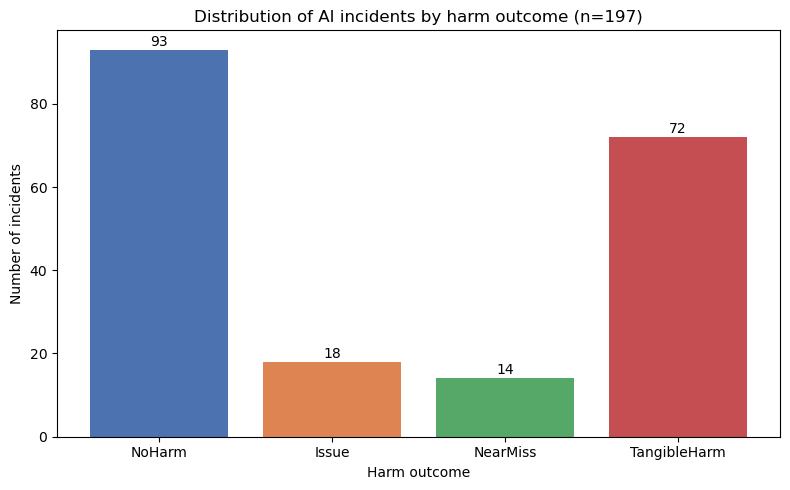

In [21]:
counts = model_df["harm_outcome"].value_counts().reindex(HARM_ORDER)

plt.figure(figsize=(8, 5))
bars = plt.bar(counts.index, counts.values, color=HARM_COLORS)
plt.title("Distribution of AI incidents by harm outcome (n=197)")
plt.ylabel("Number of incidents")
plt.xlabel("Harm outcome")
for bar, val in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, val + 1, str(val), ha="center")
plt.tight_layout()
plt.savefig("chart_outcome_distribution.png", dpi=150)
plt.show()

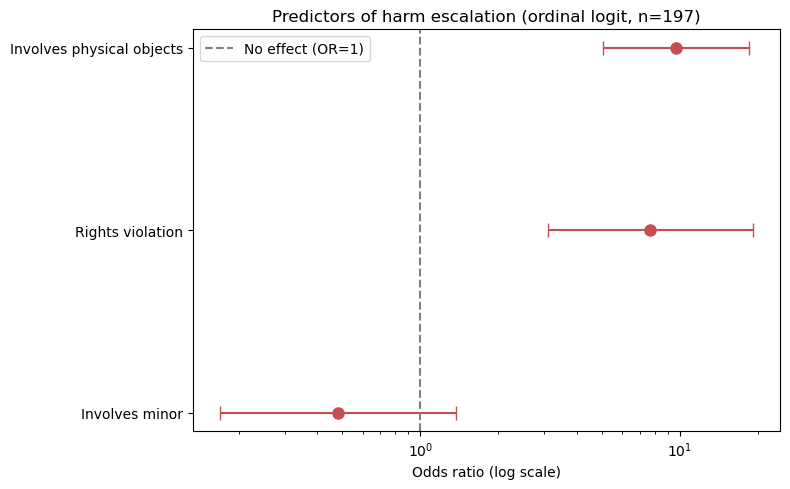

In [22]:
labels = ["Involves minor", "Rights violation", "Involves physical objects"]
ors = np.exp(res.params[:3])
ci_low = np.exp(conf.iloc[:3]["lower"])
ci_high = np.exp(conf.iloc[:3]["upper"])

plt.figure(figsize=(8, 5))
y_pos = np.arange(len(labels))
plt.errorbar(ors, y_pos, xerr=[ors - ci_low, ci_high - ors],
             fmt="o", color="#C44E52", capsize=5, markersize=8)
plt.axvline(1, color="gray", linestyle="--", label="No effect (OR=1)")
plt.yticks(y_pos, labels)
plt.xscale("log")
plt.xlabel("Odds ratio (log scale)")
plt.title("Predictors of harm escalation (ordinal logit, n=197)")
plt.legend()
plt.tight_layout()
plt.savefig("chart_odds_ratios.png", dpi=150)
plt.show()

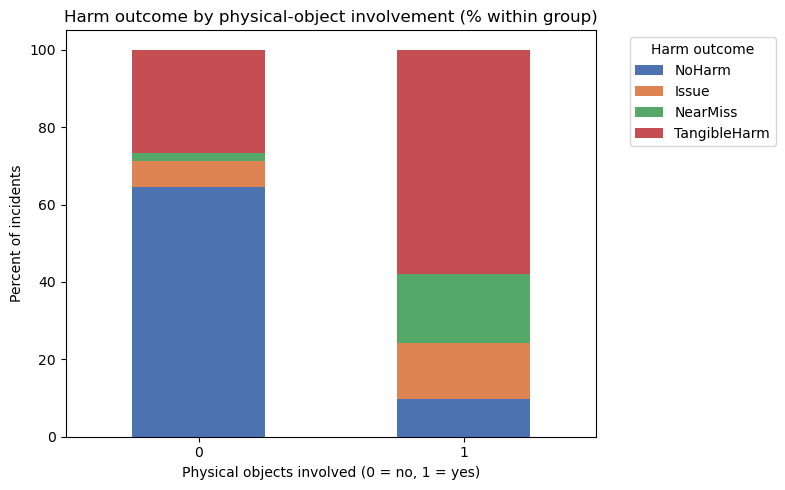

In [23]:
cross = pd.crosstab(m["physical_flag"], m["harm_outcome"], normalize="index") * 100

cross.plot(kind="bar", stacked=True, figsize=(8, 5), color=HARM_COLORS)
plt.title("Harm outcome by physical-object involvement (% within group)")
plt.ylabel("Percent of incidents")
plt.xlabel("Physical objects involved (0 = no, 1 = yes)")
plt.legend(title="Harm outcome", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart_physical_vs_outcome.png", dpi=150)
plt.show()

In [24]:
model_df.to_csv("model_df.csv", index=False)
print(f"Saved model_df.csv with {len(model_df)} rows")

Saved model_df.csv with 197 rows


## Conclusions

- **Physical-object involvement** is the strongest predictor of harm escalation (OR = 9.63, 95% CI [5.03, 18.44], p < 0.001): incidents involving physical objects are ~9.6× more likely to be in a higher harm category.
- **Rights violations** show a similar effect (OR = 7.70, 95% CI [3.09, 19.17], p < 0.001).
- **Involvement of minors** was not a significant predictor (OR = 0.48, p = 0.17).
- The full model significantly outperforms a null model (LR = 61.4, df = 3, p < 0.001) and has lower AIC than a multinomial logit (395.3 vs 499.5), supporting the proportional odds assumption.

### Limitations

- Only **197 of 990** incidents have CSETv1 Tangible Harm labels — a 20% coverage rate reflecting the volunteer annotation process, not an absence of harm.
- The AIID is subject to **reporting bias**: high-profile incidents are more likely to be catalogued, so estimates may not generalize.
- Findings are **descriptive, not causal**. The association between physical involvement and harm escalation should not be read as a causal mechanism.
- Sample size (n=197) limits statistical power for detecting small effects, and the confidence interval on `physical_flag` is wide (5.0–18.4).

### Next steps

- Validate on a random-sample audit of unannotated incidents
- Test whether the physical-object effect holds within each MIT risk domain
- Extend to a temporal analysis (does the effect strengthen over time?)